# Predicting Transaction Cluster Assignments
**Muhammad Akhtar Ariq · Supervised model comparison and evaluation**

This notebook compares Decision Tree and Random Forest classifiers on the labels
generated by the companion clustering analysis. It uses fitted preprocessing
pipelines, stratified validation, a held-out classification test set, and explicit
metric/artifact exports.

**Run:** execute the clustering notebook first, or use the committed
`data_clustering_inverse.csv`. Run all cells from the repository root with the
environment in `requirements.txt`. `BMLP_OUTPUT_DIR` redirects both the input CSV
and generated artifacts, allowing the complete workflow to run in isolation.

## 1. Target definition and evaluation protocol

`Target` is a K-Means cluster identifier, not a manually verified outcome.
The question is **how accurately can these classifiers reproduce the segmentation?**

We reserve 20% of rows using a stratified split. Categorical encoding is fitted
within each model pipeline, so both the test split and cross-validation folds
receive transformations learned only from their corresponding training rows.
Random Forest hyperparameters are selected using five shuffled, stratified folds
of the training set. All models are evaluated together after that search.

**Scope limitation:** the upstream clustering, filtering, scaling, and age bins
were fitted before this split. This holdout evaluates reproduction of a fixed,
full-dataset segmentation; it is not an independent end-to-end estimate for future
transactions. Transactions may also share an account, and this split is not
grouped by account or ordered by time.

In [1]:
from __future__ import annotations

import hashlib
import json
import os
import platform
from importlib.metadata import version
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, classification_report,
    precision_recall_fscore_support,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier

RANDOM_STATE = 42
TEST_SIZE = 0.20
CV_FOLDS = 5
N_JOBS = min(4, os.cpu_count() or 1)
TARGET_COLUMN = "Target"
CLUSTER_LABELS = [0, 1, 2]
NUMERICAL_FEATURES = (
    "TransactionAmount", "CustomerAge", "TransactionDuration",
    "LoginAttempts", "AccountBalance",
)
CATEGORICAL_FEATURES = (
    "TransactionType", "Location", "Channel", "CustomerOccupation", "AgeGroup",
)
OUTPUT_DIR = Path(os.environ.get("BMLP_OUTPUT_DIR", ".")).resolve()
DATASET_PATH = OUTPUT_DIR / "data_clustering_inverse.csv"
ASSETS_DIR = OUTPUT_DIR / "assets"
REPORTS_DIR = OUTPUT_DIR / "reports"

In [2]:
def validate_labeled_data(frame: pd.DataFrame) -> None:
    """Require complete, finite features and the expected integer cluster labels.

    Raises ValueError on an empty dataset, missing/duplicate columns, missing
    values, nonnumeric numerical features, infinite numbers, or an unexpected
    target label. This checks the clustering/classification handoff before fitting.
    """
    required = {*NUMERICAL_FEATURES, *CATEGORICAL_FEATURES, TARGET_COLUMN}
    missing = sorted(required - set(frame.columns))
    if missing:
        raise ValueError(f"Labeled dataset is missing required columns: {missing}")
    if frame.empty or not frame.columns.is_unique:
        raise ValueError("Labeled data must contain records and unique column names.")
    if frame[list(required)].isna().any().any():
        raise ValueError("Labeled data contains missing values; rerun clustering.")
    for column in NUMERICAL_FEATURES:
        if not pd.api.types.is_numeric_dtype(frame[column]):
            raise ValueError(f"{column} must contain numerical values.")
    if not np.isfinite(frame[list(NUMERICAL_FEATURES)].to_numpy(dtype=float)).all():
        raise ValueError("Labeled data contains nonfinite numerical values.")
    if not pd.api.types.is_integer_dtype(frame[TARGET_COLUMN]):
        raise ValueError("Target must contain integer cluster labels.")
    if set(frame[TARGET_COLUMN].unique()) != set(CLUSTER_LABELS):
        raise ValueError(f"Expected cluster labels {CLUSTER_LABELS}.")


def evaluate_predictions(y_true, y_pred) -> dict[str, float]:
    """Return accuracy and support-weighted precision, recall, and F1.

    Support weighting accounts for unequal cluster sizes. Undefined precision
    or recall is assigned zero; per-class reports and confusion matrices remain
    necessary because aggregate metrics can conceal a weak minority class.
    """
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="weighted", zero_division=0
    )
    return {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "precision_weighted": float(precision),
        "recall_weighted": float(recall),
        "f1_weighted": float(f1),
    }

## 2. Validate the labeled dataset

The readable export contains original feature units and category names, plus
`AgeGroup` and `Target`. Features are selected explicitly; the target is excluded
from the feature matrix. Class counts are displayed before and after splitting.

In [3]:
if not DATASET_PATH.is_file():
    raise FileNotFoundError(f"Run the clustering notebook first: {DATASET_PATH} is missing.")
for directory in (ASSETS_DIR, REPORTS_DIR):
    directory.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")

labeled_transactions = pd.read_csv(DATASET_PATH)
validate_labeled_data(labeled_transactions)
feature_columns = [column for column in labeled_transactions.columns if column in
                   {*NUMERICAL_FEATURES, *CATEGORICAL_FEATURES}]
X = labeled_transactions.loc[:, feature_columns].copy()
y = labeled_transactions[TARGET_COLUMN].copy()
display(labeled_transactions.head())
display(y.value_counts().sort_index().rename("transactions").to_frame())

,TransactionAmount,TransactionType,Location,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,AgeGroup,Target
0,14.09,Debit,San Diego,ATM,70.0,Doctor,81.0,1.0,5112.21,Tua,1
1,376.24,Debit,Houston,ATM,68.0,Doctor,141.0,1.0,13758.91,Tua,0
2,126.29,Debit,Mesa,Online,19.0,Student,56.0,1.0,1122.35,Muda,0
3,184.50,Debit,Raleigh,Online,26.0,Student,25.0,1.0,8569.06,Muda,1
4,92.15,Debit,Oklahoma City,ATM,18.0,Student,172.0,1.0,781.68,Muda,0


,transactions
Target,
0,647
1,637
2,661


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE
)
if y_train.value_counts().min() < CV_FOLDS:
    raise ValueError("Each training class needs at least one record per cross-validation fold.")

split_summary = pd.DataFrame({
    "all_rows": y.value_counts().sort_index(),
    "training": y_train.value_counts().sort_index(),
    "test": y_test.value_counts().sort_index(),
})
split_summary.index.name = TARGET_COLUMN
assert set(X_train.index).isdisjoint(X_test.index)
assert TARGET_COLUMN not in X_train.columns
display(split_summary)
print(f"Training rows: {len(X_train):,}; test rows: {len(X_test):,}")

,all_rows,training,test
Target,,,
0,647,517,130
1,637,510,127
2,661,529,132


Training rows: 1,556; test rows: 389


## 3. Fit comparable model pipelines

Tree estimators do not require numerical scaling, so original numerical values
pass through unchanged. A `ColumnTransformer` one-hot encodes categorical
features inside the pipeline. All categories are retained because tree models
do not require the reference-category drop used in linear regression.

`handle_unknown="ignore"` lets a new category pass through as an all-zero block
rather than causing an inference error; that behavior still needs monitoring
for a deployed model. No encoder is fitted on held-out rows.

In [5]:
baseline_models = {
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, random_state=RANDOM_STATE, n_jobs=N_JOBS
    ),
}
fitted_models = {}
for name, estimator in baseline_models.items():
    preprocessing = ColumnTransformer(
        transformers=[
            ("categorical", OneHotEncoder(handle_unknown="ignore", sparse_output=False),
             list(CATEGORICAL_FEATURES)),
            ("numerical", "passthrough", list(NUMERICAL_FEATURES)),
        ],
        remainder="drop",
    )
    fitted_models[name] = Pipeline([
        ("preprocessing", preprocessing), ("classifier", estimator),
    ]).fit(X_train, y_train)

display(pd.DataFrame({
    "model": list(fitted_models),
    "encoded_features": [
        len(model.named_steps["preprocessing"].get_feature_names_out())
        for model in fitted_models.values()
    ],
}))

,model,encoded_features
0,Decision Tree,60
1,Random Forest,60


## 4. Tune Random Forest using training data only

The grid contains 27 combinations of tree count, maximum depth, and minimum split
size. Five-fold stratified validation evaluates every combination. The pipeline is
cloned and refitted for each fold, including its categorical encoder. The test
set does not select hyperparameters.

Accuracy is the selection metric, matching the reference experiment. The search
parallelizes combinations; each forest inside the search uses one worker to avoid
nested parallelism. Cross-validation train/test scores are exported to inspect
overfitting and variation across folds.

In [6]:
parameter_grid = {
    "classifier__n_estimators": [50, 100, 200],
    "classifier__max_depth": [None, 10, 20],
    "classifier__min_samples_split": [2, 5, 10],
}
cross_validation = StratifiedKFold(
    n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE
)
search = GridSearchCV(
    estimator=clone(fitted_models["Random Forest"]).set_params(classifier__n_jobs=1),
    param_grid=parameter_grid,
    cv=cross_validation,
    scoring="accuracy",
    n_jobs=N_JOBS,
    pre_dispatch=N_JOBS,
    refit=True,
    return_train_score=True,
    error_score="raise",
)
search.fit(X_train, y_train)
fitted_models["Tuned Random Forest"] = search.best_estimator_

search_results = pd.DataFrame(search.cv_results_).sort_values("rank_test_score")
search_columns = [
    "param_classifier__n_estimators", "param_classifier__max_depth",
    "param_classifier__min_samples_split", "mean_train_score",
    "mean_test_score", "std_test_score", "rank_test_score",
]
display(pd.Series(search.best_params_, name="selected_value").to_frame())
print(f"Best cross-validation accuracy: {search.best_score_:.4f}")
display(search_results[search_columns].head(10))

,selected_value
classifier__max_depth,NaN
classifier__min_samples_split,2.0
classifier__n_estimators,50.0


Best cross-validation accuracy: 1.0000


,param_classifier__n_estimators,param_classifier__max_depth,param_classifier__min_samples_split,mean_train_score,mean_test_score,std_test_score,rank_test_score
0,50,None,2,1.0,1.0,0.0,1
1,100,None,2,1.0,1.0,0.0,1
2,200,None,2,1.0,1.0,0.0,1
3,50,None,5,1.0,1.0,0.0,1
4,100,None,5,1.0,1.0,0.0,1
5,200,None,5,1.0,1.0,0.0,1
6,50,None,10,1.0,1.0,0.0,1
7,100,None,10,1.0,1.0,0.0,1
8,200,None,10,1.0,1.0,0.0,1
25,100,20,10,1.0,1.0,0.0,1


## 5. Held-out classification results

Each model predicts the same held-out rows. Weighted metrics summarize the class
mix; per-class precision, recall, F1, and raw confusion counts show where errors
occur. Scores describe agreement with cluster labels, not fraud detection.
A tuned model is not assumed to improve test performance; any difference is
reported from the actual predictions.

A location diagnostic checks whether each category already determines the target.
If it does, reproducing the labels can be easy even when the segmentation itself
is not useful. Decision Tree impurity-based importance is used here to diagnose
this dependence, not to establish a causal effect of location.

In [7]:
predictions = {name: model.predict(X_test) for name, model in fitted_models.items()}
model_metrics = pd.DataFrame.from_dict({
    name: evaluate_predictions(y_test, predicted)
    for name, predicted in predictions.items()
}, orient="index")
model_metrics.index.name = "model"
display(model_metrics.style.format("{:.2%}"))

classification_reports = {}
for name, predicted in predictions.items():
    classification_reports[name] = classification_report(
        y_test, predicted, labels=CLUSTER_LABELS, output_dict=True, zero_division=0
    )
    display(Markdown(f"### {name}"))
    display(pd.DataFrame(classification_reports[name]).T.round(4))

location_label_counts = labeled_transactions.groupby("Location")[TARGET_COLUMN].nunique()
tree_pipeline = fitted_models["Decision Tree"]
transformed_names = tree_pipeline.named_steps["preprocessing"].get_feature_names_out()
tree_importances = tree_pipeline.named_steps["classifier"].feature_importances_
location_importance = float(sum(
    importance for name, importance in zip(transformed_names, tree_importances)
    if name.startswith("categorical__Location_")
))
display(Markdown(
    f"**Location diagnostic:** {int(location_label_counts.eq(1).sum())} of "
    f"{len(location_label_counts)} locations map to a single cluster in the labeled dataset. "
    f"Location indicators account for **{location_importance:.1%}** of the fitted Decision Tree's "
    "impurity-based importance. High label agreement should be interpreted in this context."
))

,accuracy,precision_weighted,recall_weighted,f1_weighted
model,,,,
Decision Tree,100.00%,100.00%,100.00%,100.00%
Random Forest,100.00%,100.00%,100.00%,100.00%
Tuned Random Forest,100.00%,100.00%,100.00%,100.00%


### Decision Tree

,precision,recall,f1-score,support
0,1.0,1.0,1.0,130.0
1,1.0,1.0,1.0,127.0
2,1.0,1.0,1.0,132.0
accuracy,1.0,1.0,1.0,1.0
macro avg,1.0,1.0,1.0,389.0
weighted avg,1.0,1.0,1.0,389.0


### Random Forest

,precision,recall,f1-score,support
0,1.0,1.0,1.0,130.0
1,1.0,1.0,1.0,127.0
2,1.0,1.0,1.0,132.0
accuracy,1.0,1.0,1.0,1.0
macro avg,1.0,1.0,1.0,389.0
weighted avg,1.0,1.0,1.0,389.0


### Tuned Random Forest

,precision,recall,f1-score,support
0,1.0,1.0,1.0,130.0
1,1.0,1.0,1.0,127.0
2,1.0,1.0,1.0,132.0
accuracy,1.0,1.0,1.0,1.0
macro avg,1.0,1.0,1.0,389.0
weighted avg,1.0,1.0,1.0,389.0


**Location diagnostic:** 43 of 43 locations map to a single cluster in the labeled dataset. Location indicators account for **100.0%** of the fitted Decision Tree's impurity-based importance. High label agreement should be interpreted in this context.

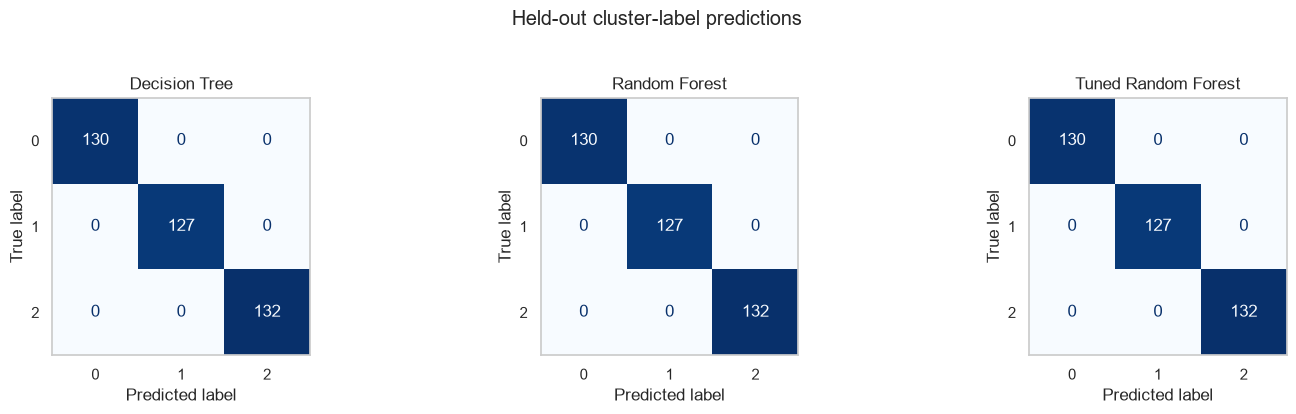

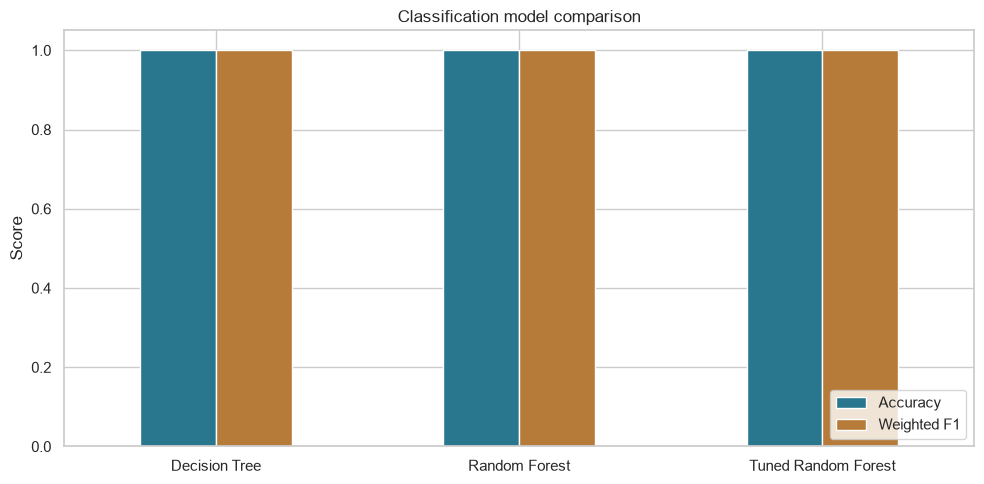

In [8]:
figure, axes = plt.subplots(1, len(fitted_models), figsize=(15, 4))
for axis, (name, predicted) in zip(axes, predictions.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, predicted, labels=CLUSTER_LABELS,
        cmap="Blues", colorbar=False, ax=axis,
    )
    axis.grid(False)
    axis.set_title(name)
figure.suptitle("Held-out cluster-label predictions", y=1.03)
figure.tight_layout()
figure.savefig(ASSETS_DIR / "classification-confusion-matrices.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(figure)

figure, axis = plt.subplots(figsize=(10, 5))
model_metrics[["accuracy", "f1_weighted"]].rename(
    columns={"accuracy": "Accuracy", "f1_weighted": "Weighted F1"}
).plot.bar(ax=axis, color=["#28778e", "#b77b39"], rot=0)
axis.set(title="Classification model comparison", xlabel="", ylabel="Score", ylim=(0, 1.05))
axis.legend(loc="lower right")
figure.tight_layout()
figure.savefig(ASSETS_DIR / "classification-model-comparison.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(figure)

## 6. Save complete estimators and evaluation evidence

Each baseline artifact now contains its fitted preprocessing pipeline as well as
the estimator. The tuned artifact contains the fitted `GridSearchCV` object,
whose `best_estimator_` is also a complete pipeline. Call `.predict()` with a
DataFrame in original feature units, using the training feature names; no manual
one-hot encoding is required.

The legacy `.h5` filenames are retained for continuity; all are Joblib files,
not HDF5. Only load trusted artifacts and use the dependency versions recorded
in the run metadata. Reports include full-precision metrics, per-class reports,
split counts, cross-validation results, and the input CSV's SHA-256 fingerprint.

In [9]:
artifact_names = {
    "Decision Tree": "decision_tree_model.h5",
    "Random Forest": "explore_RandomForest_classification.h5",
}
for name, filename in artifact_names.items():
    joblib.dump(fitted_models[name], OUTPUT_DIR / filename)
joblib.dump(search, OUTPUT_DIR / "tuning_classification.h5")

model_metrics.to_csv(REPORTS_DIR / "classification_metrics.csv")
search_results[search_columns].to_csv(REPORTS_DIR / "grid_search_results.csv", index=False)
split_summary.to_csv(REPORTS_DIR / "classification_split.csv")
(REPORTS_DIR / "classification_reports.json").write_text(
    json.dumps(classification_reports, indent=2) + "\n", encoding="utf-8"
)
classification_metadata = {
    "input_file": DATASET_PATH.name,
    "input_sha256": hashlib.sha256(DATASET_PATH.read_bytes()).hexdigest(),
    "target_definition": "K-Means assignments from full-dataset exploratory clustering",
    "training_rows": len(X_train),
    "test_rows": len(X_test),
    "feature_columns": feature_columns,
    "random_state": RANDOM_STATE,
    "test_size": TEST_SIZE,
    "cross_validation": {"folds": CV_FOLDS, "stratified": True, "shuffle": True},
    "selection_metric": "accuracy",
    "best_cv_accuracy": float(search.best_score_),
    "best_parameters": search.best_params_,
    "python": platform.python_version(),
    "versions": {package: version(package) for package in
                 ("numpy", "pandas", "scikit-learn", "matplotlib", "seaborn", "joblib")},
}
(REPORTS_DIR / "classification_metadata.json").write_text(
    json.dumps(classification_metadata, indent=2) + "\n", encoding="utf-8"
)

# Verify serialization at the boundary that downstream users will consume.
for name, filename in artifact_names.items():
    restored = joblib.load(OUTPUT_DIR / filename)
    np.testing.assert_array_equal(restored.predict(X_test), predictions[name])
restored_search = joblib.load(OUTPUT_DIR / "tuning_classification.h5")
np.testing.assert_array_equal(restored_search.predict(X_test), predictions["Tuned Random Forest"])

baseline_accuracy = model_metrics.loc["Random Forest", "accuracy"]
tuned_accuracy = model_metrics.loc["Tuned Random Forest", "accuracy"]
display(Markdown(
    f"**Observed result:** baseline Random Forest accuracy is **{baseline_accuracy:.2%}**; "
    f"tuned Random Forest accuracy is **{tuned_accuracy:.2%}** on {len(y_test):,} test rows. "
    f"The difference is **{(tuned_accuracy - baseline_accuracy) * 100:+.2f} percentage points**. "
    "These results measure reproduction of the reference segmentation."
))

**Observed result:** baseline Random Forest accuracy is **100.00%**; tuned Random Forest accuracy is **100.00%** on 389 test rows. The difference is **+0.00 percentage points**. These results measure reproduction of the reference segmentation.

## 7. Conclusions and limits

Compare the observed baseline and tuned results above rather than assuming tuning
helps. Review per-class recall and confusion counts alongside aggregate accuracy.
The saved pipelines make the classification experiment reproducible without a
separate feature-encoding step.

This experiment does not validate whether the original clusters are useful,
identify fraud, or estimate performance on later transactions. For an independent
predictive study, split the original records first, fit upstream preprocessing
and clustering on training records only, and use account-aware/time-aware
validation where appropriate. The source currently supplies no verified fraud target.